# Company A: Handset-Age Churn Targeting
**GCI World 2026 Final Assignment: Data Science and Business Consulting**
Author (Omnicampus account): SunilMandloi

**Business question.** Company A's customers churn at very different rates depending on how old their handset is. Can we use that pattern, plus a risk model, to decide *which customers to contact before they leave* and *what a retention programme can afford to spend*?

**How to run.** `pip install pandas numpy matplotlib seaborn scikit-learn scipy` (no other packages needed). Place this notebook next to the `telecom/` folder containing `Client.csv` and `Record.csv`, then run all cells top to bottom. Results are fully seeded (`SEED = 42`).

**Evidence labels used throughout.** *Observed* = computed from the supplied data. *External* = sourced market evidence (see References). *Assumption* = a labelled modelling input. *Scenario* = a proposed target, not a result.

## 1. Setup and configuration

In [1]:
import warnings, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)

def find_data_dir():
    for p in [Path("telecom"), Path("Final Assignment/telecom"), Path("../telecom"), Path("data")]:
        if (p / "Client.csv").exists() and (p / "Record.csv").exists():
            return p
    raise FileNotFoundError("Put Client.csv and Record.csv in a folder called 'telecom' next to this notebook.")

DATA_DIR = find_data_dir()
OUT = Path("outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

NAVY, TEAL, ORANGE, GREY, LIGHT, RED = "#1B2A41", "#0F7B8A", "#D9822B", "#8A94A6", "#E8ECF1", "#B23A48"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.edgecolor": GREY, "axes.labelcolor": NAVY, "text.color": NAVY,
                     "xtick.color": NAVY, "ytick.color": NAVY, "font.family": "DejaVu Sans"})
print("Data folder:", DATA_DIR.resolve())

Data folder: /home/claude/work/Final Assignment/telecom


## 2. Data loading and integration checks
The two files describe the same customers. Before merging we confirm the key is present, unique and matches 1:1, so the join cannot multiply or drop rows.

In [2]:
client = pd.read_csv(DATA_DIR / "Client.csv")
record = pd.read_csv(DATA_DIR / "Record.csv")
print(f"Client.csv : {client.shape[0]:,} rows x {client.shape[1]} cols")
print(f"Record.csv : {record.shape[0]:,} rows x {record.shape[1]} cols")

for name, d in [("Client", client), ("Record", record)]:
    print(f"{name}: missing IDs={d.Customer_ID.isna().sum()}, duplicate IDs={d.Customer_ID.duplicated().sum()}, fully duplicated rows={d.duplicated().sum()}")

ids_c, ids_r = set(client.Customer_ID), set(record.Customer_ID)
print(f"IDs in both={len(ids_c & ids_r):,}; only in Client={len(ids_c - ids_r)}; only in Record={len(ids_r - ids_c)}")

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
assert len(df) == len(record) == len(client), "Join changed the row count"
print(f"Merged     : {df.shape[0]:,} rows x {df.shape[1]} cols (one row per customer, no row multiplication)")

Client.csv : 100,000 rows x 50 cols
Record.csv : 100,000 rows x 51 cols
Client: missing IDs=0, duplicate IDs=0, fully duplicated rows=0
Record: missing IDs=0, duplicate IDs=0, fully duplicated rows=0
IDs in both=100,000; only in Client=0; only in Record=0
Merged     : 100,000 rows x 100 cols (one row per customer, no row multiplication)


## 3. Data-quality assessment
We look at missing values, duplicates, constant columns, categorical cardinality, extreme values and redundant (highly correlated) variables. Nothing is dropped automatically: each consequential decision is explained.

In [3]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
print(f"Columns with any missing value: {len(miss)} of {df.shape[1]}")
display(miss.round(1).head(15).to_frame("% missing"))

cat_cols_all = df.select_dtypes(exclude="number").columns.tolist()
print(f"\nCategorical columns: {len(cat_cols_all)}; numeric columns: {df.shape[1] - len(cat_cols_all)}")
card = df[cat_cols_all].nunique().sort_values(ascending=False)
display(card.to_frame("distinct values").T)

top_share = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
near_const = top_share[top_share > 0.99].index.tolist()
print("\nNear-constant columns (>99% one value):", near_const if near_const else "none")

print("\nRange checks")
print(f"  rev_Mean <= 0 : {(df.rev_Mean <= 0).sum():,} customers; rev_Mean max = {df.rev_Mean.max():,.0f} (99.9th pct = {df.rev_Mean.quantile(.999):,.0f})")
print(f"  eqpdays  < 0  : {(df.eqpdays < 0).sum():,}; months range = {df.months.min()}-{df.months.max()}")
print(f"  mou_Mean == 0 : {(df.mou_Mean == 0).sum():,} customers with zero minutes")

num = df.select_dtypes("number").drop(columns=["churn"])
corr = num.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("\nMost redundant numeric pairs (|r|):")
display(pairs.head(8).round(3).to_frame("|r|"))

Columns with any missing value: 43 of 100

Categorical columns: 21; numeric columns: 79

Near-constant columns (>99% one value): ['recv_sms_Mean', 'callfwdv_Mean']

Range checks
  rev_Mean <= 0 : 17 customers; rev_Mean max = 3,843 (99.9th pct = 451)
  eqpdays  < 0  : 133; months range = 6-61
  mou_Mean == 0 : 1,615 customers with zero minutes

Most redundant numeric pairs (|r|):


,% missing
numbcars,49.4
dwllsize,38.3
HHstatin,37.9
ownrent,33.7
dwlltype,31.9
lor,30.2
income,25.4
adults,23.0
infobase,22.1
hnd_webcap,10.2


,crclscod,area,ethnic,dwllsize,HHstatin,prizm_social_one,marital,dualband,new_cell,hnd_webcap,asl_flag,ownrent,refurb_new,infobase,dwlltype,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd
distinct values,54,19,17,15,6,5,5,4,3,3,2,2,2,2,2,2,2,2,2,2,2


,,|r|
totcalls,adjqty,1.000
totmou,adjmou,1.000
totrev,adjrev,0.998
plcd_vce_Mean,attempt_Mean,0.998
comp_vce_Mean,complete_Mean,0.998
ovrrev_Mean,vceovr_Mean,0.995
ccrndmou_Mean,cc_mou_Mean,0.989
attempt_Mean,complete_Mean,0.986


**Reading of the quality checks.** The join is clean. Missingness is concentrated in the household-demographic fields; usage and billing fields are almost complete. We therefore keep all columns, impute inside the modelling pipeline (median plus a "was missing" flag, so missingness itself can carry signal), and fit all data-dependent steps on training data only. The redundant pairs are lifetime totals vs their adjusted versions (e.g. `totmou`/`adjmou`) and attempted vs completed calls; they are harmless for the tree models and are regularised in the logistic model. Two near-constant usage columns (`recv_sms_Mean`, `callfwdv_Mean`) are kept because they cost nothing. 133 customers have a negative handset age (0.1%) and 17 have zero or negative revenue; we keep them, since the models are robust to them and removing them would not change any conclusion.

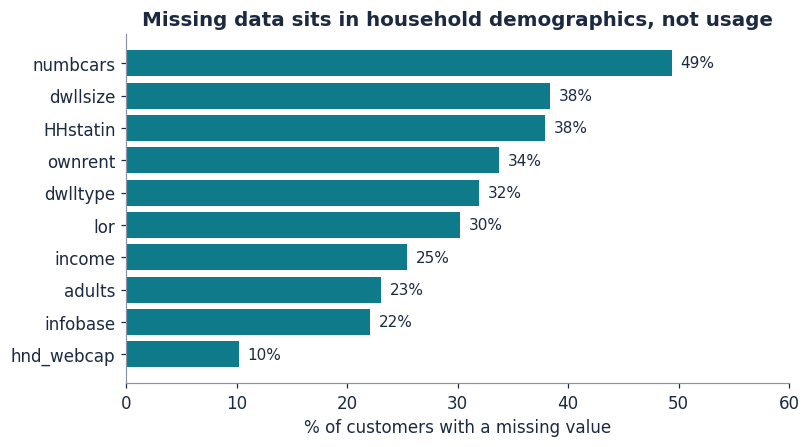

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
m = miss.head(10).sort_values()
ax.barh(m.index, m.values, color=TEAL)
for i, v in enumerate(m.values): ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=10)
ax.set_xlabel("% of customers with a missing value"); ax.set_xlim(0, 60)
ax.set_title("Missing data sits in household demographics, not usage")
fig.tight_layout(); fig.savefig(FIG / "fig_missing.png"); plt.show()

## 4. Target definition
`churn` is supplied in `Record.csv`: 1 = the customer left 31-60 days after the observation date, 0 = stayed. This is a **binary classification** task. No date column exists, so a true time-based validation is not possible; we state that as a limitation.

In [5]:
y_all = df["churn"]
print(y_all.value_counts().rename({0: "stayed", 1: "churned"}).to_frame("customers").assign(share=lambda t: (t.customers / len(df)).round(4)))
SAMPLE_CHURN_RATE = y_all.mean()
print(f"\nChurn rate in this file = {SAMPLE_CHURN_RATE:.1%}. Real postpaid churn at large US carriers is about 1% per month (see References),")
print("so the file is enriched with churners. Rankings and relative lift transfer; raw precision and accuracy do not. Section 12 rescales them.")

         customers   share
churn                     
stayed       50438  0.5044
churned      49562  0.4956

Churn rate in this file = 49.6%. Real postpaid churn at large US carriers is about 1% per month (see References),
so the file is enriched with churners. Rankings and relative lift transfer; raw precision and accuracy do not. Section 12 rescales them.


## 5. Exploratory analysis: what separates churners?
We first screen every numeric variable by its stand-alone ability to rank churners (single-feature ROC-AUC). This both finds the strongest signals and doubles as a leakage check: a near-perfect single feature would indicate a variable that encodes the outcome.

In [6]:
from sklearn.metrics import roc_auc_score
single = {}
for col in num.columns.drop("Customer_ID"):
    x = df[col].fillna(df[col].median())
    a = roc_auc_score(y_all, x); single[col] = max(a, 1 - a)
single = pd.Series(single).sort_values(ascending=False)
display(single.head(10).round(3).to_frame("single-feature AUC"))
print(f"Strongest single feature AUC = {single.iloc[0]:.3f} -> no variable trivially encodes the target (no obvious leakage).")

Strongest single feature AUC = 0.574 -> no variable trivially encodes the target (no obvious leakage).


,single-feature AUC
eqpdays,0.574
hnd_price,0.558
totmrc_Mean,0.542
mou_opkv_Mean,0.541
mou_cvce_Mean,0.541
mou_Mean,0.539
iwylis_vce_Mean,0.536
mouiwylisv_Mean,0.536
complete_Mean,0.536
opk_vce_Mean,0.536


### 5.1 Handset age is the sharpest signal
`eqpdays` = days the customer has used the current handset. If churn were smooth in handset age we would see a gentle slope. Instead we test for a step.

Churn <=300 days: 39.5% (n=40,088) | 301-400 days: 59.3% (n=20,866) | difference = 19.9 points, chi-square p = 0.00e+00


,size,rate
eq_band,,
<=100,10663,0.401
101-150,4916,0.443
151-200,6940,0.401
201-250,9252,0.378
251-300,8317,0.372
301-350,11581,0.610
351-400,9285,0.573
401-500,11476,0.527
501-700,15267,0.539


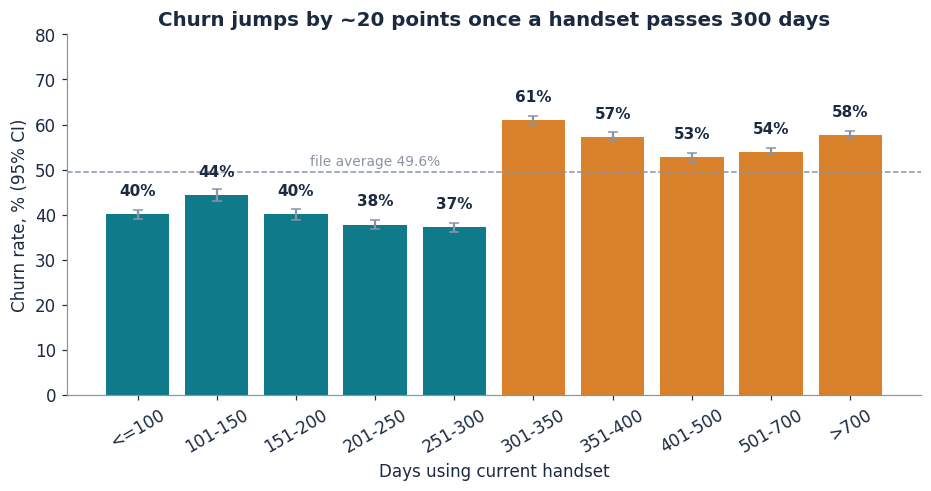

In [7]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    a = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - a) / d, (c + a) / d

edges = [-np.inf, 100, 150, 200, 250, 300, 350, 400, 500, 700, np.inf]
labels = ["<=100", "101-150", "151-200", "201-250", "251-300", "301-350", "351-400", "401-500", "501-700", ">700"]
df["eq_band"] = pd.cut(df.eqpdays, edges, labels=labels)
g = df.groupby("eq_band", observed=True).churn.agg(["sum", "size"])
g["rate"] = g["sum"] / g["size"]
ci = np.array([wilson(k, n) for k, n in zip(g["sum"], g["size"])])
g["lo"], g["hi"] = ci[:, 0], ci[:, 1]
display(g.assign(rate=lambda t: t.rate.round(3))[["size", "rate"]])

fig, ax = plt.subplots(figsize=(8.6, 4.6))
cols = [TEAL if i < 5 else ORANGE for i in range(len(g))]
ax.bar(g.index.astype(str), g.rate * 100, color=cols, yerr=[(g.rate - g.lo) * 100, (g.hi - g.rate) * 100], capsize=3, ecolor=GREY)
ax.axhline(SAMPLE_CHURN_RATE * 100, color=GREY, ls="--", lw=1); ax.text(3, SAMPLE_CHURN_RATE * 100 + 1.4, "file average 49.6%", ha="center", color=GREY, fontsize=9)
for i, r in enumerate(g.rate): ax.text(i, r * 100 + 4.2, f"{r*100:.0f}%", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 80); ax.set_ylabel("Churn rate, % (95% CI)"); ax.set_xlabel("Days using current handset")
ax.set_title("Churn jumps by ~20 points once a handset passes 300 days")
plt.xticks(rotation=30); fig.tight_layout(); fig.savefig(FIG / "fig_eqpdays.png"); plt.show()

low, high = df[df.eqpdays <= 300].churn, df[(df.eqpdays > 300) & (df.eqpdays <= 400)].churn
t = np.array([[low.sum(), len(low) - low.sum()], [high.sum(), len(high) - high.sum()]])
chi2, p, *_ = stats.chi2_contingency(t)
print(f"Churn <=300 days: {low.mean():.1%} (n={len(low):,}) | 301-400 days: {high.mean():.1%} (n={len(high):,}) | difference = {100*(high.mean()-low.mean()):.1f} points, chi-square p = {p:.2e}")

**Robustness: is the step just a tenure effect?** Handset age and customer tenure are linked (a 300-day-old handset needs at least ~10 months of life). We repeat the comparison within tenure groups.

eq3,<=300 d,301-400 d,>400 d
tenure_grp,,,
<=12 months,37.0,63.3,NaN
13-24 months,45.5,55.8,53.9
>24 months,36.2,48.4,56.0


eq3,<=300 d,301-400 d,>400 d
tenure_grp,,,
<=12 months,20411.0,12032.0,NaN
13-24 months,12272.0,6546.0,24049.0
>24 months,7405.0,2288.0,14996.0


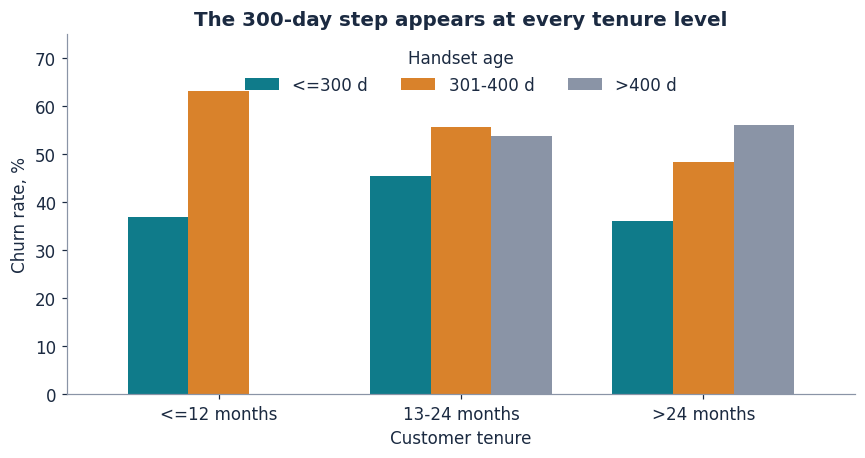

In [8]:
df["tenure_grp"] = pd.cut(df.months, [0, 12, 24, 100], labels=["<=12 months", "13-24 months", ">24 months"])
df["eq3"] = pd.cut(df.eqpdays, [-np.inf, 300, 400, np.inf], labels=["<=300 d", "301-400 d", ">400 d"])
piv = df.pivot_table(index="tenure_grp", columns="eq3", values="churn", aggfunc="mean", observed=True) * 100
cnt = df.pivot_table(index="tenure_grp", columns="eq3", values="churn", aggfunc="size", observed=True)
display(piv.round(1)); display(cnt)

fig, ax = plt.subplots(figsize=(8, 4.3))
piv.plot(kind="bar", ax=ax, color=[TEAL, ORANGE, GREY], width=0.75, rot=0)
ax.set_ylabel("Churn rate, %"); ax.set_xlabel("Customer tenure"); ax.set_ylim(0, 75)
ax.set_title("The 300-day step appears at every tenure level")
ax.legend(title="Handset age", frameon=False, ncol=3, loc="upper center")
fig.tight_layout(); fig.savefig(FIG / "fig_eq_tenure.png"); plt.show()

### 5.2 Other commercially relevant patterns
Revenue, usage trend, customer-care contact and handset price, each cut into groups with the number of customers shown so that small groups are not over-read.

revenue | churn range across groups: 48.5% to 52.9% | smallest group n = 19923
usage change | churn range across groups: 45.6% to 54.0% | smallest group n = 19792
care calls | churn range across groups: 44.1% to 51.8% | smallest group n = 10291
handset price | churn range across groups: 41.0% to 57.5% | smallest group n = 10963


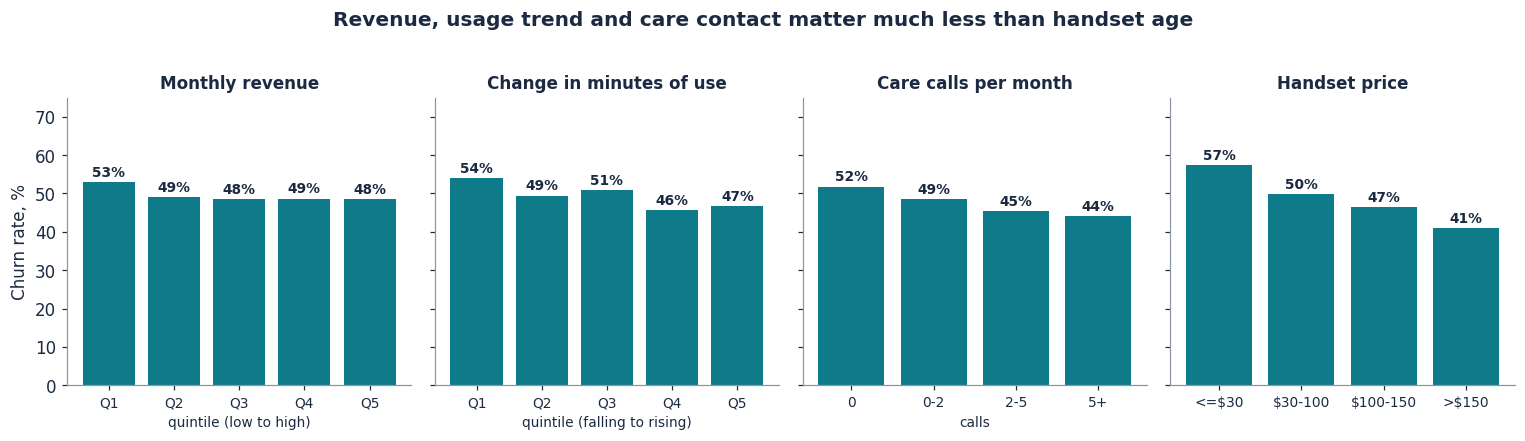

In [9]:
def rate_table(col, bins=None, q=None, lbl=None):
    s = pd.qcut(df[col], q, duplicates="drop") if q else pd.cut(df[col], bins, labels=lbl)
    t = df.groupby(s, observed=True).churn.agg(["mean", "size"])
    return t

rev = rate_table("rev_Mean", q=5); chg = rate_table("change_mou", q=5)
care = rate_table("custcare_Mean", bins=[-1, 0, 2, 5, 10_000], lbl=["0", "0-2", "2-5", "5+"])
price = rate_table("hnd_price", bins=[0, 30, 100, 150, 1000], lbl=["<=$30", "$30-100", "$100-150", ">$150"])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.9), sharey=True)
for ax, (t, ttl, xl) in zip(axes, [(rev, "Monthly revenue", "quintile (low to high)"), (chg, "Change in minutes of use", "quintile (falling to rising)"),
                                   (care, "Care calls per month", "calls"), (price, "Handset price", "")]):
    ax.bar(range(len(t)), t["mean"] * 100, color=TEAL)
    for i, (m_, n_) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m_ * 100 + 1.5, f"{m_*100:.0f}%", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f"Q{i+1}" for i in range(len(t))] if "quintile" in xl else [str(i) for i in t.index], fontsize=9)
    ax.set_title(ttl, fontsize=11); ax.set_xlabel(xl, fontsize=9); ax.set_ylim(0, 75)
axes[0].set_ylabel("Churn rate, %")
fig.suptitle("Revenue, usage trend and care contact matter much less than handset age", fontweight="bold", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "fig_other.png", bbox_inches="tight"); plt.show()
for nm, t in [("revenue", rev), ("usage change", chg), ("care calls", care), ("handset price", price)]:
    print(nm, "| churn range across groups:", f"{t['mean'].min():.1%} to {t['mean'].max():.1%}", "| smallest group n =", int(t['size'].min()))

### 5.3 Where age and price combine, and which area to pilot
Handset age and price together, and churn by regional area (the `area` field holds US-style regions; this is the only geographic information in the data).

Smallest cell n = 1769
New York City Area: 11,098 customers (11.1% of base), churn 50.0% vs file 49.6%


,mean,size
area,,
NEW YORK CITY AREA,50.0,11098
LOS ANGELES AREA,49.8,6636
DC/MARYLAND/VIRGINIA AREA,46.0,6567
MIDWEST AREA,45.9,6346
SOUTHWEST AREA,51.0,6187
ATLANTIC SOUTH AREA,49.0,6132


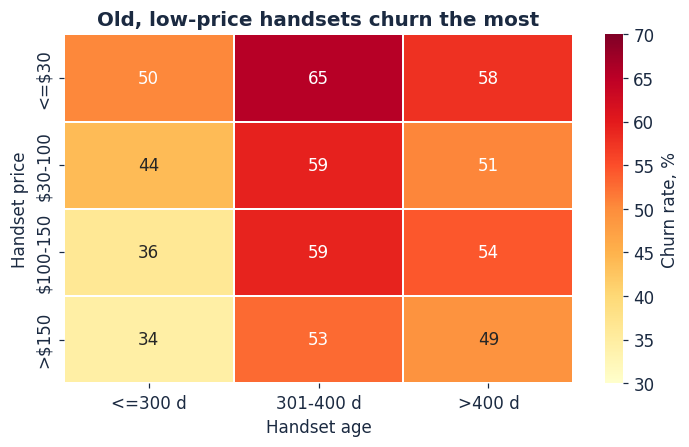

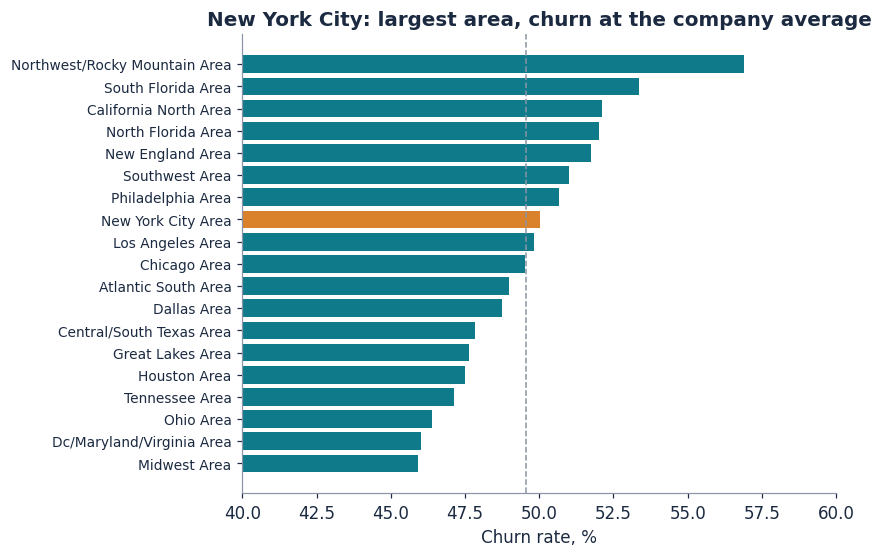

In [10]:
df["price_t"] = pd.cut(df.hnd_price, [0, 30, 100, 150, 1000], labels=["<=$30", "$30-100", "$100-150", ">$150"])
h = df.pivot_table(index="price_t", columns="eq3", values="churn", aggfunc="mean", observed=True) * 100
hn = df.pivot_table(index="price_t", columns="eq3", values="churn", aggfunc="size", observed=True)
fig, ax = plt.subplots(figsize=(6.6, 4.2))
sns.heatmap(h, annot=True, fmt=".0f", cmap="YlOrRd", vmin=30, vmax=70, cbar_kws={"label": "Churn rate, %"}, ax=ax, linewidths=1, linecolor="white")
ax.set_xlabel("Handset age"); ax.set_ylabel("Handset price"); ax.set_title("Old, low-price handsets churn the most")
fig.tight_layout(); fig.savefig(FIG / "fig_age_price.png"); plt.show()
print("Smallest cell n =", int(hn.min().min()))

ar = df.groupby("area").churn.agg(["mean", "size"]).sort_values("size", ascending=False)
display(ar.head(6).assign(mean=lambda t: (t["mean"] * 100).round(1)))
fig, ax = plt.subplots(figsize=(8, 5.2))
a2 = ar.sort_values("mean")
ax.barh([i.title() for i in a2.index], a2["mean"] * 100, color=[ORANGE if i == "NEW YORK CITY AREA" else TEAL for i in a2.index])
ax.axvline(SAMPLE_CHURN_RATE * 100, color=GREY, ls="--", lw=1)
ax.set_xlabel("Churn rate, %"); ax.set_xlim(40, 60); ax.set_title("New York City: largest area, churn at the company average")
ax.tick_params(axis="y", labelsize=9)
fig.tight_layout(); fig.savefig(FIG / "fig_area.png"); plt.show()
nyc = ar.loc["NEW YORK CITY AREA"]
print(f"New York City Area: {int(nyc['size']):,} customers ({nyc['size']/len(df):.1%} of base), churn {nyc['mean']:.1%} vs file {SAMPLE_CHURN_RATE:.1%}")

### 5.4 How concentrated is the opportunity?
If a simple rule (handset older than 300 days but not extreme) already captured most churners, a model would add little. We measure how much of the base and of all churners that cohort contains.

In [11]:
cohort = (df.eqpdays > 300) & (df.eqpdays <= 400)
share_base = cohort.mean(); share_churn = cohort[df.churn == 1].mean(); share_stay = cohort[df.churn == 0].mean()
print(f"Cohort 301-400 days: {cohort.sum():,} customers = {share_base:.1%} of base, churn {df.churn[cohort].mean():.1%}")
print(f"It holds {share_churn:.1%} of all churners but also {share_stay:.1%} of non-churners -> useful but not selective on its own.")

Cohort 301-400 days: 20,866 customers = 20.9% of base, churn 59.3%
It holds 25.0% of all churners but also 16.8% of non-churners -> useful but not selective on its own.


## 6. Prediction setup and leakage review
**Decision to support.** Each month, rank customers by risk of leaving in the next 31-60 days so that a limited retention budget goes to the right people. The model only needs the information that exists at the observation date.

Leakage review (documented, not assumed): the table lists every exclusion and every judgement call. The data has no timestamps, so we cannot prove that each column was recorded *before* the outcome window; we rely on the dataset description and on the single-feature check in section 5 (no variable above AUC 0.58).

In [12]:
import json
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV, cross_val_predict, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, QuantileTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score,
                             f1_score, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, partial_dependence

TARGET, ID = "churn", "Customer_ID"
FAIRNESS_EXCLUDED = ["ethnic"]
HELPERS = ["eq_band", "tenure_grp", "eq3", "price_t"]          # columns created for charts above
X = df.drop(columns=[ID, TARGET] + HELPERS + FAIRNESS_EXCLUDED)
y = df[TARGET]
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

leak_log = pd.DataFrame([
    ("Customer_ID", "Excluded", "Identifier; carries no behavioural information"),
    ("churn", "Target", "Outcome to predict (leaving 31-60 days after observation date)"),
    ("ethnic", "Excluded", "Protected characteristic: not used for targeting customers (fairness and compliance)"),
    ("totrev, totmou, adjrev, adjmou, totcalls, adjqty", "Kept, flagged", "Lifetime totals up to the observation date; cannot verify timestamps, so treated as historical"),
    ("churn-adjacent fields (cancellation, port-out, retention-offer)", "None present", "No such columns exist in the data dictionary or files"),
    ("Single-feature screen", "Passed", f"Highest stand-alone AUC = {single.iloc[0]:.3f}; nothing trivially encodes churn"),
], columns=["Item", "Decision", "Reason"])
display(leak_log)
print(f"Model inputs: {len(num_cols)} numeric + {len(cat_cols)} categorical = {X.shape[1]} features")

Model inputs: 77 numeric + 20 categorical = 97 features


,Item,Decision,Reason
0,Customer_ID,Excluded,Identifier; carries no behavioural information
1,churn,Target,Outcome to predict (leaving 31-60 days after observation date)
2,ethnic,Excluded,Protected characteristic: not used for targeting customers (fairness and compliance)
3,"totrev, totmou, adjrev, adjmou, totcalls, adjqty","Kept, flagged","Lifetime totals up to the observation date; cannot verify timestamps, so treated as historical"
4,"churn-adjacent fields (cancellation, port-out, retention-offer)",None present,No such columns exist in the data dictionary or files
5,Single-feature screen,Passed,Highest stand-alone AUC = 0.574; nothing trivially encodes churn


## 7. Train/test design
80% training, 20% untouched test, stratified on churn, fixed seed. **All** imputation, scaling and encoding is inside scikit-learn pipelines and is fitted on training folds only. Hyper-parameters are tuned with 3-fold cross-validation on the training set. Models are *selected* on cross-validated ROC-AUC; the test set is used once, to report final scores.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print(f"Train: {len(X_train):,} rows (churn {y_train.mean():.1%}) | Test: {len(X_test):,} rows (churn {y_test.mean():.1%})")

pre_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("qt", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False))]), cat_cols),
])
pre_rf = ColumnTransformer([
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("oe", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), cat_cols),
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
])
pre_hgb = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan), cat_cols),
    ("num", "passthrough", num_cols),
])
cat_mask = [True] * len(cat_cols) + [False] * len(num_cols)
CV_RESULTS, FITTED = {}, {}

Train: 80,000 rows (churn 49.6%) | Test: 20,000 rows (churn 49.6%)


## 8. Models
* **Dummy baseline** (always predicts the training churn rate): the floor any model must beat.
* **Logistic regression**: transparent, regularised linear baseline.
* **Random forest**: many decision trees averaged; captures non-linear effects such as the 300-day step.
* **Gradient boosting** (scikit-learn `HistGradientBoostingClassifier`): trees built one after another, each correcting the last; tuned by randomised search.

`xgboost` is not required; scikit-learn's gradient boosting is the same model family and keeps the notebook dependency-light.

In [14]:
t0 = time.time()
dummy = Pipeline([("pre", pre_hgb), ("model", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)
CV_RESULTS["Dummy (prior)"] = (0.5, 0.0); FITTED["Dummy (prior)"] = dummy

lr_gs = GridSearchCV(Pipeline([("pre", pre_linear), ("model", LogisticRegression(max_iter=600, solver="lbfgs"))]),
                     {"model__C": [0.003, 0.03, 0.3]}, scoring="roc_auc", cv=cv, n_jobs=1).fit(X_train, y_train)
i = lr_gs.best_index_
CV_RESULTS["Logistic regression"] = (lr_gs.cv_results_["mean_test_score"][i], lr_gs.cv_results_["std_test_score"][i])
FITTED["Logistic regression"] = lr_gs.best_estimator_
print(f"Logistic regression best C = {lr_gs.best_params_['model__C']} | CV ROC-AUC = {CV_RESULTS['Logistic regression'][0]:.4f} +/- {CV_RESULTS['Logistic regression'][1]:.4f} ({time.time()-t0:.0f}s)")

Logistic regression best C = 0.3 | CV ROC-AUC = 0.6408 +/- 0.0009 (129s)


In [15]:
t0 = time.time()
rf = Pipeline([("pre", pre_rf), ("model", RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=40,
                                                                  max_features="sqrt", random_state=SEED, n_jobs=1))])
s = cross_val_score(rf, X_train, y_train, scoring="roc_auc", cv=cv, n_jobs=1)
CV_RESULTS["Random forest"] = (s.mean(), s.std()); FITTED["Random forest"] = rf.fit(X_train, y_train)
print(f"Random forest CV ROC-AUC = {s.mean():.4f} +/- {s.std():.4f} ({time.time()-t0:.0f}s)")

Random forest CV ROC-AUC = 0.6730 +/- 0.0044 (114s)


In [16]:
t0 = time.time()
hgb = Pipeline([("pre", pre_hgb), ("model", HistGradientBoostingClassifier(
    max_iter=400, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
    categorical_features=cat_mask, random_state=SEED))])
space = {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_leaf_nodes": [15, 31, 63],
         "model__min_samples_leaf": [50, 100, 200], "model__l2_regularization": [0.0, 1.0, 10.0]}
hgb_rs = RandomizedSearchCV(hgb, space, n_iter=6, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1).fit(X_train, y_train)
i = hgb_rs.best_index_
CV_RESULTS["Gradient boosting"] = (hgb_rs.cv_results_["mean_test_score"][i], hgb_rs.cv_results_["std_test_score"][i])
FITTED["Gradient boosting"] = hgb_rs.best_estimator_
print("Best gradient-boosting settings:", {k.replace("model__", ""): v for k, v in hgb_rs.best_params_.items()})
print(f"Gradient boosting CV ROC-AUC = {CV_RESULTS['Gradient boosting'][0]:.4f} +/- {CV_RESULTS['Gradient boosting'][1]:.4f} ({time.time()-t0:.0f}s)")

Best gradient-boosting settings: {'min_samples_leaf': 100, 'max_leaf_nodes': 31, 'learning_rate': 0.03, 'l2_regularization': 1.0}
Gradient boosting CV ROC-AUC = 0.6893 +/- 0.0034 (210s)


## 9. Final evaluation on the untouched test set
Metrics reported: ROC-AUC (principal metric: it measures how well the model *ranks* customers, which is what a capacity-limited campaign needs), precision-recall AUC, accuracy (with its limits), precision, recall and F1 at the default 0.50 cut-off, and the Brier score (probability accuracy; lower is better).

In [17]:
def evaluate(name, model):
    p = model.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
    return {"Model": name, "CV ROC-AUC": CV_RESULTS[name][0], "Test ROC-AUC": roc_auc_score(y_test, p),
            "Test PR-AUC": average_precision_score(y_test, p), "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0), "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0), "Brier": brier_score_loss(y_test, p)}, p

rows, PRED = [], {}
for nm, mdl in FITTED.items():
    r, p = evaluate(nm, mdl); rows.append(r); PRED[nm] = p
results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))
results.round(4).to_csv(OUT / "model_results.csv")

BEST = max([m for m in CV_RESULTS if m != "Dummy (prior)"], key=lambda m: CV_RESULTS[m][0])
print(f"\nSelected model (highest cross-validated ROC-AUC, chosen before looking at the test set): {BEST}")
rng = np.random.default_rng(SEED); pb = PRED[BEST]; yt = y_test.values
boot = [roc_auc_score(yt[ix], pb[ix]) for ix in (rng.integers(0, len(yt), len(yt)) for _ in range(300))]
AUC_CI = (np.percentile(boot, 2.5), np.percentile(boot, 97.5))
print(f"{BEST}: test ROC-AUC = {results.loc[BEST, 'Test ROC-AUC']:.4f} (95% bootstrap interval {AUC_CI[0]:.4f}-{AUC_CI[1]:.4f}); baseline = 0.5000")
cm = confusion_matrix(y_test, (pb >= 0.5).astype(int)); print("Confusion matrix at 0.50 [rows: actual stayed/churned; cols: predicted stayed/churned]\n", cm)


Selected model (highest cross-validated ROC-AUC, chosen before looking at the test set): Gradient boosting
Gradient boosting: test ROC-AUC = 0.6934 (95% bootstrap interval 0.6866-0.7006); baseline = 0.5000
Confusion matrix at 0.50 [rows: actual stayed/churned; cols: predicted stayed/churned]
 [[6332 3756]
 [3516 6396]]


,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Accuracy,Precision,Recall,F1,Brier
Model,,,,,,,,
Dummy (prior),0.5000,0.5000,0.4956,0.5044,0.0000,0.0000,0.0000,0.2500
Logistic regression,0.6408,0.6440,0.6297,0.6073,0.6091,0.5800,0.5942,0.2344
Random forest,0.6730,0.6755,0.6577,0.6231,0.6140,0.6450,0.6291,0.2282
Gradient boosting,0.6893,0.6934,0.6809,0.6364,0.6300,0.6453,0.6376,0.2212


**How to read this.** An AUC of 0.5 is a coin flip and 1.0 is perfect. Churn here is only moderately predictable (explained further below), which is typical for telecom data without call-centre or contract-end information. Accuracy near 0.64 is *not* a good headline number on its own: because the file is almost 50/50, accuracy says nothing about how rare real churn is. The business value comes from ranking and targeting, tested next.

## 10. Calibration and base-rate correction
A campaign needs *probabilities*, not just a ranking. Two steps, both fitted on training data only:
1. **Platt scaling** on out-of-fold training predictions makes the scores honest probabilities for this (50/50) file.
2. **Prior-shift correction** rescales them to a realistic base rate. Base case = **1.0% per month** (External: T-Mobile reports 0.99% postpaid account churn for Q2 2026, Verizon 0.92% overall churn and AT&T 0.86% postpaid phone churn; definitions differ, so 1.0% is a labelled assumption). It is not claimed to be Company A's true rate.

Brier score on test: raw = 0.2212, calibrated = 0.2211 (lower is better)


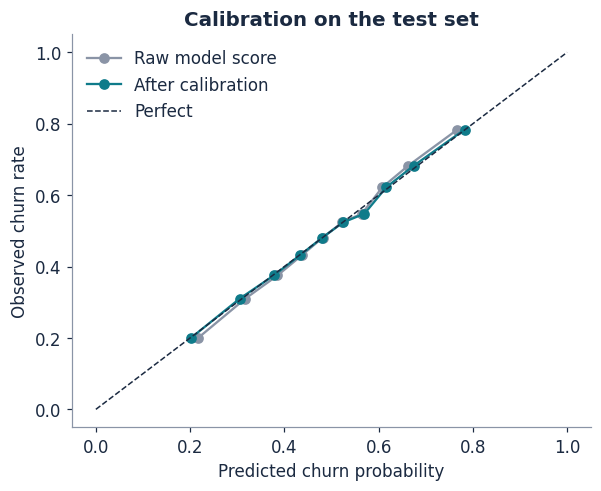

In [18]:
best = FITTED[BEST]
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]

def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
platt = LogisticRegression(C=1e6).fit(logit(oof).reshape(-1, 1), y_train)
def calibrated(p): return platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]
PI_SAMPLE = float(y_train.mean())
def to_real_world(p_cal, pi_real):
    z = logit(p_cal) + np.log(pi_real / (1 - pi_real)) - np.log(PI_SAMPLE / (1 - PI_SAMPLE))
    return 1 / (1 + np.exp(-z))

p_raw = PRED[BEST]; p_cal = calibrated(p_raw)
print(f"Brier score on test: raw = {brier_score_loss(y_test, p_raw):.4f}, calibrated = {brier_score_loss(y_test, p_cal):.4f} (lower is better)")
fig, ax = plt.subplots(figsize=(5.6, 4.6))
for p_, lab, c in [(p_raw, "Raw model score", GREY), (p_cal, "After calibration", TEAL)]:
    fr, mp = calibration_curve(y_test, p_, n_bins=10, strategy="quantile"); ax.plot(mp, fr, "o-", color=c, label=lab)
ax.plot([0, 1], [0, 1], "--", color=NAVY, lw=1, label="Perfect"); ax.set_xlabel("Predicted churn probability"); ax.set_ylabel("Observed churn rate")
ax.set_title("Calibration on the test set"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig_calibration.png"); plt.show()

## 11. Targeting analysis: how well does the ranking concentrate churners?
Rank the test customers by predicted risk. A campaign with limited capacity contacts only the top slice, so we report churn rate and lift per decile, and how much of all churn the top 5%, 10% and 20% capture.

Precision at a 1% base rate uses Bayes' rule on the file's true-positive and false-positive rates: it answers 'of the people we contact, what share would really have churned?'


,customers,churn_rate,lift_vs_avg,cum_recall
decile,,,,
1,2000,0.784,1.581,0.158
2,2000,0.682,1.376,0.296
3,2000,0.622,1.255,0.421
4,2000,0.548,1.106,0.532
5,2000,0.524,1.057,0.638
6,2000,0.481,0.971,0.735
7,2000,0.432,0.871,0.822
8,2000,0.375,0.757,0.897
9,2000,0.310,0.626,0.960


,Share of base,Churn rate in file,Recall (share of churners caught),Lift in file,Precision at 1% base rate,Lift at 1% base rate
Selection,,,,,,
Model: top 5% by risk,0.050,0.846,0.085,1.707,0.053,5.346
Model: top 10% by risk,0.100,0.784,0.158,1.581,0.036,3.587
Model: top 20% by risk,0.200,0.733,0.296,1.479,0.027,2.741
Rule: handset 301-400 days,0.209,0.598,0.253,1.207,0.015,1.509


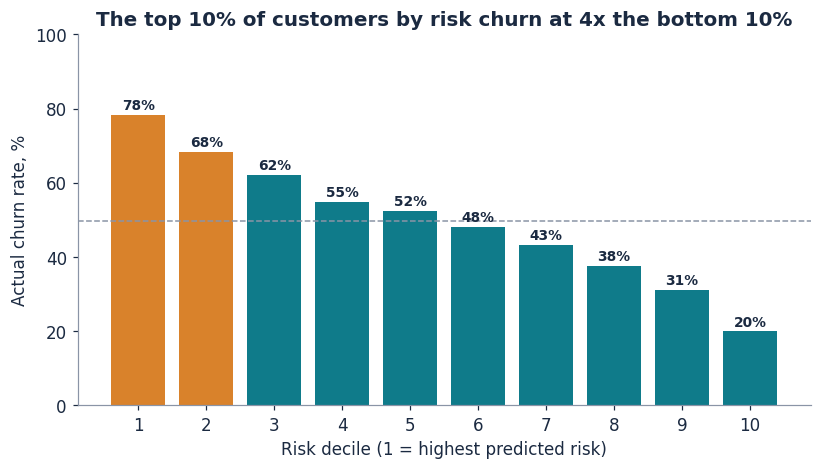

In [19]:
order = np.argsort(-p_raw); ys = y_test.values[order]; n = len(ys)
dec = pd.DataFrame({"decile": np.repeat(np.arange(1, 11), int(np.ceil(n / 10)))[:n], "churn": ys})
dt = dec.groupby("decile").churn.agg(["size", "mean"]).rename(columns={"size": "customers", "mean": "churn_rate"})
dt["lift_vs_avg"] = dt.churn_rate / ys.mean(); dt["cum_recall"] = dt.churn_rate.mul(dt.customers).cumsum() / ys.sum()
display(dt.round(3))

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.bar(dt.index, dt.churn_rate * 100, color=[ORANGE if d <= 2 else TEAL for d in dt.index])
for d, r in dt.churn_rate.items(): ax.text(d, r * 100 + 1.5, f"{r*100:.0f}%", ha="center", fontsize=9, fontweight="bold")
ax.axhline(ys.mean() * 100, color=GREY, ls="--", lw=1); ax.set_xticks(range(1, 11))
ax.set_xlabel("Risk decile (1 = highest predicted risk)"); ax.set_ylabel("Actual churn rate, %"); ax.set_ylim(0, 100)
ax.set_title("The top 10% of customers by risk churn at 4x the bottom 10%")
fig.tight_layout(); fig.savefig(FIG / "fig_deciles.png"); plt.show()

def at_top(frac):
    k = int(frac * n); tp = ys[:k].sum(); fp = k - tp; P, N = ys.sum(), n - ys.sum()
    return k, tp / k, tp / P, fp / N
def realworld_precision(tpr, fpr, pi): return tpr * pi / (tpr * pi + fpr * (1 - pi))

PI_BASE = 0.01
rows = []
for frac in (0.05, 0.10, 0.20):
    k, prec, tpr, fpr = at_top(frac)
    rows.append({"Selection": f"Model: top {int(frac*100)}% by risk", "Share of base": frac, "Churn rate in file": prec, "Recall (share of churners caught)": tpr,
                 "Lift in file": prec / ys.mean(), "Precision at 1% base rate": realworld_precision(tpr, fpr, PI_BASE),
                 "Lift at 1% base rate": realworld_precision(tpr, fpr, PI_BASE) / PI_BASE})
rule = (X_test.eqpdays > 300) & (X_test.eqpdays <= 400)
tpr_r, fpr_r = rule[y_test == 1].mean(), rule[y_test == 0].mean(); prec_r = y_test[rule].mean()
rows.append({"Selection": "Rule: handset 301-400 days", "Share of base": rule.mean(), "Churn rate in file": prec_r, "Recall (share of churners caught)": tpr_r,
             "Lift in file": prec_r / ys.mean(), "Precision at 1% base rate": realworld_precision(tpr_r, fpr_r, PI_BASE),
             "Lift at 1% base rate": realworld_precision(tpr_r, fpr_r, PI_BASE) / PI_BASE})
targeting = pd.DataFrame(rows).set_index("Selection"); display(targeting.round(3))
targeting.round(4).to_csv(OUT / "targeting_table.csv")
print("Precision at a 1% base rate uses Bayes' rule on the file's true-positive and false-positive rates: it answers 'of the people we contact, what share would really have churned?'")

**What this means.** The model concentrates churners well *in relative terms* (top-decile lift in the file; several-fold lift at a realistic 1% base rate). But at a realistic base rate, the large majority of contacted customers would have stayed anyway, so every offer must be cheap, and its causal effect must be measured in a controlled test (section 14). A simple handset-age rule is a useful screen but is much less selective than the model.

## 12. What drives the predictions? (predictive, not causal)
Permutation importance: shuffle one variable on the test set and measure how much ROC-AUC falls. A bigger drop means the model leans on that variable more. This shows what is *predictive*; it does not show that changing a variable would change behaviour.

**Reading:** customer tenure (`months`) and handset age (`eqpdays`) are the two biggest drivers, followed by the change in minutes of use and total minutes. Handset age is the strongest *single* variable in the exploratory screen, but the model combines it with tenure and usage trend. Only handset age and tenure are things Company A can plan an offer around today; usage trend is a warning sign, not a lever.

,AUC drop when shuffled
months,0.0394
eqpdays,0.0329
change_mou,0.0308
mou_Mean,0.0291
totmrc_Mean,0.0139
avgqty,0.0129
crclscod,0.0094
uniqsubs,0.0069
hnd_price,0.0060
area,0.0044


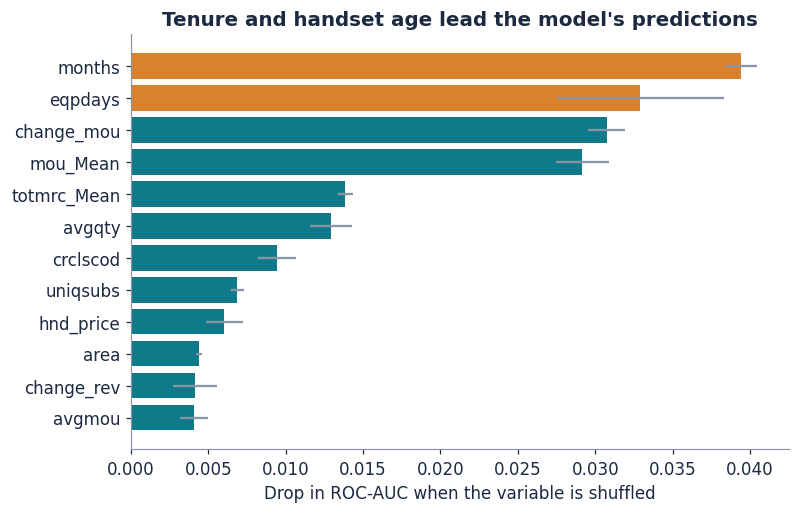

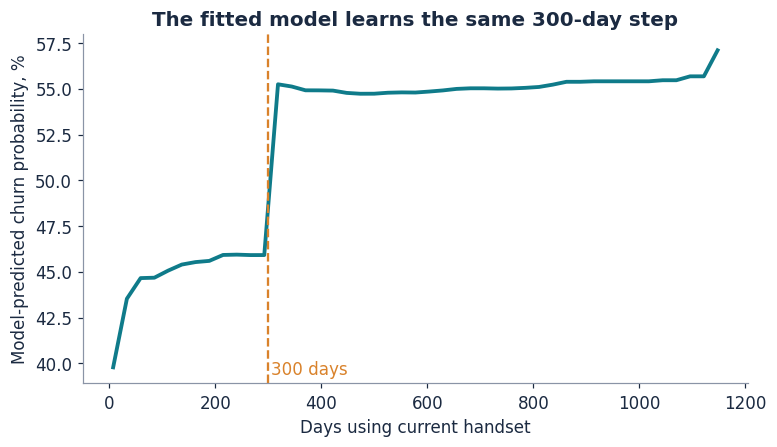

In [20]:
samp = X_test.sample(6000, random_state=SEED); ysamp = y_test.loc[samp.index]
pi_imp = permutation_importance(best, samp, ysamp, scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi_imp.importances_mean, index=samp.columns).sort_values(ascending=False)
imp_sd = pd.Series(pi_imp.importances_std, index=samp.columns).loc[imp.index]
display(imp.head(12).round(4).to_frame("AUC drop when shuffled"))

fig, ax = plt.subplots(figsize=(7.4, 4.8)); top = imp.head(12).iloc[::-1]
ax.barh(top.index, top.values, xerr=imp_sd.loc[top.index].values, color=[ORANGE if i in ("eqpdays", "months") else TEAL for i in top.index], ecolor=GREY)
ax.set_xlabel("Drop in ROC-AUC when the variable is shuffled"); ax.set_title("Tenure and handset age lead the model's predictions")
fig.tight_layout(); fig.savefig(FIG / "fig_importance.png"); plt.show()

pdp = partial_dependence(best, X_test.sample(3000, random_state=SEED), ["eqpdays"], grid_resolution=45, percentiles=(0.01, 0.99), kind="average")
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(pdp["grid_values"][0], np.array(pdp["average"][0]) * 100, color=TEAL, lw=2.5)
ax.axvline(300, color=ORANGE, ls="--"); ax.text(305, ax.get_ylim()[0] + 0.5, "300 days", color=ORANGE)
ax.set_xlabel("Days using current handset"); ax.set_ylabel("Model-predicted churn probability, %"); ax.set_title("The fitted model learns the same 300-day step")
fig.tight_layout(); fig.savefig(FIG / "fig_pdp.png"); plt.show()

## 13. Does it work equally well across groups?
A basic fairness and robustness check. We did not use `ethnic`, but we still compare ranking quality across the main areas and tenure groups to look for large gaps.

In [21]:
tt = df.loc[X_test.index, ["area", "months"]].copy(); tt["y"] = y_test.values; tt["p"] = p_raw
tt["tenure"] = pd.cut(tt.months, [0, 12, 24, 100], labels=["<=12 mo", "13-24 mo", ">24 mo"])
def grp_auc(col):
    return tt.groupby(col, observed=True).apply(lambda g: pd.Series({"customers": len(g), "ROC-AUC": roc_auc_score(g.y, g.p), "mean score": g.p.mean()}))
ga = grp_auc("area").sort_values("customers", ascending=False); display(ga.round(3).head(8))
display(grp_auc("tenure").round(3))
print(f"AUC range across areas: {ga['ROC-AUC'].min():.3f} to {ga['ROC-AUC'].max():.3f} (areas with >=500 test customers: {(ga.customers>=500).sum()} of {len(ga)})")
print('Ranking quality is similar across areas but clearly better for customers in their first year (AUC about 0.75) than for 13-24 month customers (about 0.65); monitoring should be by tenure group.')

AUC range across areas: 0.640 to 0.734 (areas with >=500 test customers: 18 of 19)
Ranking quality is similar across areas but clearly better for customers in their first year (AUC about 0.75) than for 13-24 month customers (about 0.65); monitoring should be by tenure group.


,customers,ROC-AUC,mean score
area,,,
NEW YORK CITY AREA,2260.0,0.701,0.501
DC/MARYLAND/VIRGINIA AREA,1338.0,0.694,0.475
LOS ANGELES AREA,1284.0,0.696,0.492
ATLANTIC SOUTH AREA,1243.0,0.711,0.495
SOUTHWEST AREA,1241.0,0.697,0.511
MIDWEST AREA,1237.0,0.698,0.467
CALIFORNIA NORTH AREA,1197.0,0.680,0.517
NEW ENGLAND AREA,1087.0,0.697,0.509


,customers,ROC-AUC,mean score
tenure,,,
<=12 mo,6412.0,0.749,0.464
13-24 mo,8723.0,0.650,0.517
>24 mo,4865.0,0.682,0.502


In [22]:
RESULTS = {
    "n_customers": int(len(df)), "n_features": int(X.shape[1]), "sample_churn_rate": float(SAMPLE_CHURN_RATE),
    "selected_model": BEST, "seed": SEED,
    "models": {m: {k: float(v) for k, v in results.loc[m].items()} for m in results.index},
    "auc_ci": [float(AUC_CI[0]), float(AUC_CI[1])],
    "deciles": dt.round(4).reset_index().to_dict("records"),
    "targeting": targeting.round(4).reset_index().to_dict("records"),
    "top_features": imp.head(10).round(4).to_dict(),
    "pi_sample_train": PI_SAMPLE, "pi_base": PI_BASE,
}
json.dump(RESULTS, open(OUT / "results.json", "w"), indent=2)
print("Saved outputs/results.json, model_results.csv, targeting_table.csv")

Saved outputs/results.json, model_results.csv, targeting_table.csv


## 14. Business case: what can a retention programme afford to spend?
**Proposal.** Each month score every customer; contact only the highest-risk slice with a *low-cost* handset-upgrade/plan-review message (Arm A "nudge"); test a small credit (Arm B "incentive") only in a controlled trial. Success is measured against a hold-out group that is scored but not contacted.

**Formulas (all per monthly campaign wave, for a customer book of 100,000, the size of the supplied file):**
* Customers contacted `N = share contacted x book`
* Would-be churners among them `C = N x average real-world churn probability of the contacted group` (calibrated model, 1% base rate)
* Customers retained by the campaign `S = C x s`, where `s` is the *incremental* save rate (the share of would-be churners the contact actually keeps). **The model does not tell us `s`; it is a scenario input to be measured in the pilot.**
* Value per retained customer `V = average monthly revenue of contacted group x contribution margin x months retained`
* Gross benefit `= S x V`; variable cost `= N x (contact cost + acceptance rate x incentive)`; net variable benefit = gross benefit - variable cost
* Annual view = 12 waves (simplification: ignores repeated contact with the same customer); net benefit = annual net variable benefit - fixed programme cost; ROI = net benefit / total programme cost.

**Evidence labels.** The 1% churn rate is External-anchored (see section 10). Revenue is *observed* (`rev_Mean`, currency not stated; USD is an **assumption**). Contribution margin, months retained, contact cost, incentive, acceptance rate, save rate and fixed cost are all **assumptions or scenarios**, not measurements; Company A should replace them with its own figures.

In [23]:
BOOK = 100_000
rev_fill = df.loc[X_train.index, "rev_Mean"].median()          # training median fills the few missing revenue values
rev_test = df.loc[X_test.index, "rev_Mean"].clip(lower=0).fillna(rev_fill).values
print(f"Missing rev_Mean in test set filled with the training median (${rev_fill:.2f}): {df.loc[X_test.index, 'rev_Mean'].isna().sum()} customers")
order = np.argsort(-p_raw)

A = dict(pi=0.0099, margin=0.40, months=12, contact=0.75, accept=0.15, incentive=20.0, fixed=60_000)

def design(frac, pi, s, margin, months, contact, accept=0.0, incentive=0.0, book=BOOK):
    k = int(round(frac * len(p_raw))); top = order[:k]
    p_r = to_real_world(p_cal, pi)[top]
    N = frac * book; C = N * p_r.mean(); S = C * s
    V = rev_test[top].mean() * margin * months
    gross = S * V; cost = N * (contact + accept * incentive)
    return dict(treated=N, expected_churners=C, churn_prob=p_r.mean(), avg_monthly_rev=rev_test[top].mean(),
                value_per_save=V, saved=S, gross=gross, var_cost=cost, net_var=gross - cost,
                breakeven_s=(contact + accept * incentive) / (p_r.mean() * V))

rows = []
for frac in (0.05, 0.10, 0.20):
    a = design(frac, A["pi"], 0, A["margin"], A["months"], A["contact"])
    b = design(frac, A["pi"], 0, A["margin"], A["months"], A["contact"], A["accept"], A["incentive"])
    rows.append({"Contacted share": f"top {int(frac*100)}%", "Contacted / wave": a["treated"], "Real-world churn prob.": a["churn_prob"],
                 "Would-be churners / wave": a["expected_churners"], "Avg monthly revenue ($, assumed USD)": a["avg_monthly_rev"],
                 "Value per save ($)": a["value_per_save"], "Break-even save rate, Arm A nudge ($0.75)": a["breakeven_s"],
                 "Break-even save rate, Arm B incentive ($3.75)": b["breakeven_s"]})
unit = pd.DataFrame(rows).set_index("Contacted share"); display(unit.round(3))
unit.round(4).to_csv(OUT / "unit_economics.csv")
print("Break-even save rate = share of would-be churners the contact must keep for the wave to pay for itself.")

Missing rev_Mean in test set filled with the training median ($48.26): 64 customers
Break-even save rate = share of would-be churners the contact must keep for the wave to pay for itself.


,Contacted / wave,Real-world churn prob.,Would-be churners / wave,"Avg monthly revenue ($, assumed USD)",Value per save ($),"Break-even save rate, Arm A nudge ($0.75)","Break-even save rate, Arm B incentive ($3.75)"
Contacted share,,,,,,,
top 5%,5000.0,0.052,262.090,46.640,223.872,0.064,0.320
top 10%,10000.0,0.040,401.256,52.476,251.884,0.074,0.371
top 20%,20000.0,0.030,608.384,55.274,265.313,0.093,0.465


### 14.1 Conservative, base and upside scenarios (Arm A nudge)
Scenario ranges for churn use the spread of reported carrier rates (0.86% to 1.04%); all other inputs are labelled assumptions. The fixed programme cost ($60,000 per year) is a **placeholder** for analytics build, campaign operations and measurement; Company A should replace it.

In [24]:
SCEN = {"Conservative": dict(pi=0.0086, s=0.03, margin=0.30, months=6, contact=1.00),
        "Base": dict(pi=0.0099, s=0.06, margin=0.40, months=12, contact=0.75),
        "Upside": dict(pi=0.0104, s=0.10, margin=0.50, months=12, contact=0.50)}
rows = []
for frac in (0.05, 0.10):
    for nm, p in SCEN.items():
        d = design(frac, p["pi"], p["s"], p["margin"], p["months"], p["contact"])
        annual = 12 * d["net_var"]; total_cost = 12 * d["var_cost"] + A["fixed"]; net = annual - A["fixed"]
        rows.append({"Contacted": f"top {int(frac*100)}%", "Scenario": nm, "Save rate s": p["s"], "Saved / year": 12 * d["saved"],
                     "Gross benefit / yr ($)": 12 * d["gross"], "Variable cost / yr ($)": 12 * d["var_cost"], "Fixed cost / yr ($)": A["fixed"],
                     "Net benefit / yr ($)": net, "ROI %": 100 * net / total_cost,
                     "Break-even book size (customers)": A["fixed"] / (annual / BOOK) if annual > 0 else np.nan})
scen = pd.DataFrame(rows).set_index(["Contacted", "Scenario"])
display(scen.round(1)); scen.round(2).to_csv(OUT / "scenarios.csv")
print("Net benefit is for a 100,000-customer book. 'Break-even book size' = customers needed before annual net variable benefit covers the fixed cost (NaN = never, in that scenario).")

Net benefit is for a 100,000-customer book. 'Break-even book size' = customers needed before annual net variable benefit covers the fixed cost (NaN = never, in that scenario).


Save rate s  Saved / year  Gross benefit / yr ($)  Variable cost / yr ($)  Fixed cost / yr ($)  Net benefit / yr ($)  ROI %  Break-even book size (customers)
Contacted Scenario                                                                                                                                                                   
top 5%    Conservative          0.0          82.6                  6930.8                 60000.0                60000             -113069.2  -94.2                               NaN
          Base                  0.1         188.7                 42245.7                 45000.0                60000              -62754.3  -59.8                               NaN
          Upside                0.1         329.5                 92202.9                 30000.0                60000                2202.9    2.4                           96458.6
top 10%   Conservative          0.0         126.2                 11918.7                120000.0                60000             -168081.3  -93.4                               NaN
          Base                  0.1         288.9                 72770.3                 90000.0                60000              -77229.7  -51.5                               NaN
          Upside                0.1         504.8                158924.9                 60000.0                60000               38924.9   32.4                           60652.1

### 14.2 Sensitivity: which assumptions decide the answer?
Net variable benefit per wave (book of 100,000, top 5% contacted, base margin and months), across the two most uncertain inputs: the save rate and the cost of each contact.

One-at-a-time change in annual net variable benefit, base case top 5% (base value in brackets):
Base annual net variable benefit = $-2,754


,"Low case, $/yr","High case, $/yr","Swing, $"
Assumption (low / high),,,
Save rate 3% / 10% (6%),-23877.0,25409.0,49287.0
Contact cost $1.00 / $0.50 ($0.75),-17754.0,12246.0,30000.0
Margin 30% / 50% (40%),-13316.0,7807.0,21123.0
Months retained 6 / 12 (12),-23877.0,-2754.0,21123.0
Churn base rate 0.86% / 1.04% (0.99%),-8036.0,-743.0,7293.0


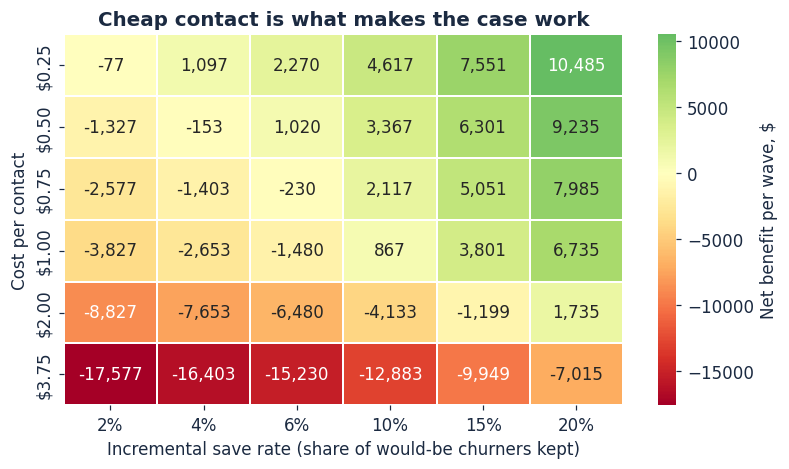

In [25]:
S_GRID = [0.02, 0.04, 0.06, 0.10, 0.15, 0.20]; C_GRID = [0.25, 0.50, 0.75, 1.00, 2.00, 3.75]
grid = pd.DataFrame([[design(0.05, A["pi"], s, A["margin"], A["months"], c)["net_var"] for s in S_GRID] for c in C_GRID],
                    index=[f"${c:.2f}" for c in C_GRID], columns=[f"{int(s*100)}%" for s in S_GRID])
fig, ax = plt.subplots(figsize=(7.4, 4.4))
sns.heatmap(grid, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Net benefit per wave, $"}, ax=ax, linewidths=1, linecolor="white")
ax.set_xlabel("Incremental save rate (share of would-be churners kept)"); ax.set_ylabel("Cost per contact")
ax.set_title("Cheap contact is what makes the case work")
fig.tight_layout(); fig.savefig(FIG / "fig_sensitivity.png"); plt.show()

print("One-at-a-time change in annual net variable benefit, base case top 5% (base value in brackets):")
base = 12 * design(0.05, A["pi"], 0.06, A["margin"], A["months"], A["contact"])["net_var"]
tests = {"Save rate 3% / 10% (6%)": [dict(s=0.03), dict(s=0.10)], "Contact cost $1.00 / $0.50 ($0.75)": [dict(contact=1.0), dict(contact=0.5)],
         "Margin 30% / 50% (40%)": [dict(margin=0.3), dict(margin=0.5)], "Months retained 6 / 12 (12)": [dict(months=6), dict(months=12)],
         "Churn base rate 0.86% / 1.04% (0.99%)": [dict(pi=0.0086), dict(pi=0.0104)]}
base_kw = dict(pi=A["pi"], s=0.06, margin=A["margin"], months=A["months"], contact=A["contact"])
tor = []
for nm, variants in tests.items():
    vals = [12 * design(0.05, **{**base_kw, **v})["net_var"] for v in variants]
    tor.append({"Assumption (low / high)": nm, "Low case, $/yr": vals[0], "High case, $/yr": vals[1], "Swing, $": abs(vals[1] - vals[0])})
tor = pd.DataFrame(tor).set_index("Assumption (low / high)").sort_values("Swing, $", ascending=False)
print(f"Base annual net variable benefit = ${base:,.0f}"); display(tor.round(0))

### 14.3 How big must a pilot be to measure the save rate?
Because only about 5% of the contacted group would really churn in a month, a test needs many customers to detect a real effect. Sample size per arm (treated vs hold-out) for 80% power and a two-sided 5% test, by the relative reduction in churn probability the offer achieves.

In [26]:
def n_per_arm(p0, rel, alpha=0.05, power=0.80):
    p1 = p0 * (1 - rel); pb = (p0 + p1) / 2
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za * np.sqrt(2 * pb * (1 - pb)) + zb * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p0 - p1) ** 2))
rows = []
for frac in (0.05, 0.10, 0.20):
    k = int(frac * len(p_raw)); p0 = to_real_world(p_cal, A["pi"])[order[:k]].mean()
    rows.append({"Contacted slice": f"top {int(frac*100)}%", "Churn prob. in slice": p0, **{f"n per arm for {int(r*100)}% effect": n_per_arm(p0, r) for r in (0.10, 0.20, 0.30)}})
power = pd.DataFrame(rows).set_index("Contacted slice"); display(power.round(4)); power.to_csv(OUT / "pilot_sizing.csv")
nyc_n = int((df.area == "NEW YORK CITY AREA").sum())
print(f"The supplied file has {nyc_n:,} New York City Area customers. A real pilot needs the true New York subscriber count from Company A: the numbers above are the minimum per arm.")

The supplied file has 11,098 New York City Area customers. A real pilot needs the true New York subscriber count from Company A: the numbers above are the minimum per arm.


,Churn prob. in slice,n per arm for 10% effect,n per arm for 20% effect,n per arm for 30% effect
Contacted slice,,,,
top 5%,0.0524,27033,6420,2702
top 10%,0.0401,35748,8484,3568
top 20%,0.0304,47607,11293,4747


In [27]:
FIN = {"assumptions": A, "unit_economics": unit.round(4).reset_index().to_dict("records"),
       "scenarios": scen.round(2).reset_index().to_dict("records"), "pilot_sizing": power.round(4).reset_index().to_dict("records"),
       "sensitivity_base_annual": float(base)}
RESULTS["finance"] = FIN
json.dump(RESULTS, open(OUT / "results.json", "w"), indent=2)
print("Updated outputs/results.json with the financial model")

Updated outputs/results.json with the financial model


## 15. Limitations and next steps
**What the evidence supports.** Churn risk is strongly linked to handset age (a step at about 300 days that persists within every tenure group) and to tenure and usage trend. The model ranks customers materially better than chance (test ROC-AUC 0.693 vs 0.500) and concentrates churners in the top decile.

**Economics (section 14).** Because only about 5% of contacted customers would really churn in a month, the case is thin. Under base assumptions a $0.75 nudge to the top 5% just misses break-even (it needs a 6.4% save rate; 6% is assumed), and a $20 credit accepted by 15% of contacts would need roughly a 32% save rate. Only the upside scenario covers the $60,000 placeholder fixed cost on a 100,000-customer book. The honest conclusion is a *conditional* case: scale, a very cheap contact channel and a *measured* save rate decide it, so the next step is a low-cost measurement pilot with a stop rule, not a full rollout.

**What it does not establish.**
* *Association, not cause.* Nothing here shows that upgrading a handset, or contacting a customer, *reduces* churn. The save rate is unknown until a controlled test measures it.
* *Enriched sample.* Churn is 49.6% in the file versus about 1% per month at large US carriers. Rankings and relative lift carry over; raw precision, accuracy and counts do not, which is why section 14 rescales them (and the true base rate for Company A must be supplied).
* *No dates.* There is no timestamp, so we cannot run a time-based validation or confirm that every column pre-dates the outcome window.
* *Moderate predictability.* An AUC of about 0.69 is useful for prioritising, not for predicting individuals; ranking is better for first-year customers (AUC about 0.75) than for 13-24 month customers (about 0.65).
* *Currency and market.* Currency is not stated (USD assumed); regions are US-style and anonymised, and the dataset is not claimed to come from any named carrier.
* *Financial inputs.* Margin, costs, save rates and fixed cost are assumptions; the fixed cost is a placeholder.
* *Fairness.* `ethnic` is excluded; other demographic fields (for example `income`, `marital`) remain and should be reviewed for proxy effects before deployment.

**Next steps.** (1) Replace the placeholder inputs with Company A's churn rate, margins and campaign costs. (2) Run a randomised hold-out pilot sized per section 14.3. (3) Monitor ROC-AUC and calibration monthly by tenure group and re-train on drift. (4) Only after a measured positive save rate, test a small credit (Arm B).

## 16. Sources
External figures used in this notebook (full list in `references.md`; accessed October 2026):
1. T-Mobile US, "T-Mobile Delivers Continued Strong Account Growth, Translating into Industry-Leading Service Revenue Growth Driven by Widening Differentiation", Q2 2026 results press release, 22 July 2026 (Business Wire): postpaid account churn 0.99% (Q2 2026), 1.04% (Q1 2026), 0.92% (Q2 2025). https://www.businesswire.com/news/home/20260722580890/en/ *Primary source.*
2. Verizon Q2 2026 earnings call, 24 July 2026: consumer postpaid phone churn 0.84%. Overall churn 0.92% as reported by Customer Experience Dive: https://www.customerexperiencedive.com/news/verizon-fight-churn-cx-investments/826174/ *Company statement via secondary reporting.*
3. AT&T Q2 2026 results (22 July 2026): postpaid phone churn 0.86%, as reported by The Desk (https://thedesk.net/2026/07/att-q2-2026-earnings-report-fiber-buildout/) and PhoneArena (https://www.phonearena.com/news/at-t-adds-more-postpaid-phone-subscribers-during-q2_id182058). *Secondary reporting of a company release.*
4. ChatGPT conversation used in preparing the assignment: https://chatgpt.com/share/6acccf90-6cd0-83ec-84bf-165da7064fe2
5. Claude (Anthropic) was also used to help build the analysis, notebook and slides; every number in this notebook is produced by the code above.
Definitions differ across carriers (account churn vs phone churn), so these figures are used only as an order-of-magnitude anchor.